# 서포트벡터머신

<img src = "./ML_전체이미지/svm.png">

- 범주를 나눠줄 수 있는 최적의 구분선(결정경계선)을 찾아내어 관측치의 범주를 예측하는 모델

- 로지스틱 회귀나 판별분석에 비해 비선형 데이터에서 높은 정확도를 보이며 다른 모델들 보다 과적합 되는 경향이 적음

- SVM은 결정경계선(Decision boundary)의 양쪽의 빈 공간 마진(Margin)을 최대화하도록 만들어졌음
    - 마진과 맞닿아서 결정경계선의 위치와 각도를 정해줄 수 있는 기준이 되는 관측치를 서포트 벡터(support vector)라고 함
        - 결정경계선을 지지(support)해주고 있기 때문
     
    - svm은 서포트벡터만으로 범주의 구분 기준인 결정경계선을 정하기 때문에 학습효율이 높음
 
    - 마진은 결정경계선과 서포트 벡터와의 거리를 의미
 
- 기계학습에서 거리(distance)를 통해 분류나 회귀 모델을 만드는 경우에는 데이터 정규화나 표준화를 해두는 것을 추천
    - 변수마다 단위가 다르게 되면 모델 성능이 매우 떨어지기 때문
 
- 독립변수가 2개라면 2차원상의 결정경계선을 표현할 수 있음
    - 독립변수가 3개로 늘어나면, 결정경계선은 평면(plane)이 됨
    - 그 이상으로 차원이 증가하면 그림으로 표현할 수 없는 초평면(hyperplane)이 결정경계선이 됨
    - 따라서 SVM은 MMH(Maximum Marginal Hyperplane, 최대 마진 초평면)을 찾아 범주를 분리하는 분류 방법
 
- 하지만 대부분의 데이터는 이상치가 있을 수 있음
    - 결정경계선을 만들 때 이상치를 허용하지 않는 경우에는 과적합 문제가 발생할 가능성이 있음
 
    - 따라서 어느정도 이상치를 허용해주도록 하여 두 범주를 정확하게 나누지는 않지만 마진을 최대화하여 과적합을 방지할 수 있음
        - 이런 개념을 소프트 마진(soft margin) 이라고 함
        - 반대로 이상치를 허용하지 않는 것을 하드 마진(hard margin)이라고 함

<img src = "./ML_전체이미지/svm_soft_hard.png">

- 소프트 마진과 하드 마진을 조정해주는 매개변수로는 C와 Gamma 가 사용됨
    - C값을 낮게 설정하면 이상치들이 있을 가능성을 높게 잡아서 마진 오류를 더 많이 허용함
        - 마진 오류란 결정 경계와 마진 사이, 또는 마진 내부에 위치하는 훈련 데이터 포인트
        - 모델이 더 단순해지고 일반화 가능성이 높아질 수 있지만 너무 낮게 설정하면 모델이 너무 단순해져서 데이터의 구조를 충분히 학습하지 못할 수 있음(과소적합)
 
    - C값을 높게 설정하면 이상치들이 있을 가능성을 낮게 잡아서 마진 오류를 적게 허용함
        - 즉, 분류 오류에 대해 높은 페널티를 부여하여, 오류를 최소화
        - 이는 모델이 훈련 데이터에 더 정확히 맞추려고 하지만, 동시에 과대적합될 위험이 커짐
        - 따라서 훈련 데이터에는 잘 맞지만 새로운 데이터에는 잘 일반화되지 않을 수 있음
     
- Gamma 값은 관측치가 영향력을 행사하는 거리를 조정해주는 것

- 값이 클수록 영향력의 거리는 짧아지고, 값이 작을수록 영향력의 거리는 길어짐
    - 커질수록 각각의 관측치에 대한 결정경계선 범위가 작아짐
    - gamma 값이 커지면 여러 개의 결정경계선이 생기게 될 수 있음

<img src = "./ML_전체이미지/svm_gamma.png">

- 위와 같은 데이터 분포에서는 아무리 소프트마진을 높게 설정하더라도 결정경계선을 만들기 힘들고, 만든다고 하더라도 성능이 떨어지게 됨
    - 그런 경우 사용하는 것이 커널 기법(Kernel trick)
 
- 커널 기법은 기존의 데이터를 고차원 공간으로 확장하여 새로운 결정경계선을 만들어내는 방법
    - 커널 기법에는 Polynomial 커널, Sigmoid 커널, 가우시안 RBF 커널 등 다양한 종류가 있음
 
- SVM 모델을 만들 때는 C값과 Gamma 값을 잘 조정해 가면서 모델의 복잡도를 적정 수준으로 맞춰줘야 함

- 각 조건의 모델의 정확도, 검증 데이터셋의 오분류율 증감을 확인해가면서 과대적합과 과소적합 사이의 최적의 모델을 만들어야 함

In [1]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
import pandas as pd
import mglearn
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_excel("./data/Raisin_Dataset.xlsx")

In [3]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [4]:
# 독립변수 스케일링
x = df.drop(["Area", "Class"], axis = 1)
y = df["Class"]

In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, stratify = y,
                                                    random_state = 26)

In [6]:
mm = MinMaxScaler()
scaled_x_train = mm.fit_transform(x_train)
scaled_x_test = mm.transform(x_test)

In [7]:
print(scaled_x_train.shape, scaled_x_test.shape)

(630, 6) (270, 6)


In [8]:
# 기본 SVM 모델 성능 확인
svm = SVC()

svm.fit(scaled_x_train, y_train)
print(svm.score(scaled_x_train, y_train))
print(svm.score(scaled_x_test, y_test))

0.861904761904762
0.9


In [9]:
# 시각화를 위한 차원 축소
pca = PCA(n_components = 2)
pca_data = pca.fit_transform(scaled_x_train)

In [10]:
pca_data

array([[ 0.13071882,  0.01992917],
       [-0.33115457, -0.17518237],
       [-0.2517709 ,  0.07674677],
       ...,
       [-0.07857767, -0.13111589],
       [-0.5548061 ,  0.43613212],
       [-0.47535123,  0.29564473]])

In [13]:
# SVM C값 1 ~ 30 에 따른 모델 성능 확인

scores = []

for c_point in range(1, 31):
    svc = SVC(C = c_point)
    svc.fit(scaled_x_train, y_train)
    train_score = svc.score(scaled_x_train, y_train)
    test_score = svc.score(scaled_x_test, y_test)

    print(f"SVM : C : {c_point}, train score : {train_score:.4f}, test score : {test_score:.4f}")

    scores.append([train_score, test_score])

SVM : C : 1, train score : 0.8619, test score : 0.9000
SVM : C : 2, train score : 0.8603, test score : 0.8963
SVM : C : 3, train score : 0.8619, test score : 0.8926
SVM : C : 4, train score : 0.8635, test score : 0.8963
SVM : C : 5, train score : 0.8635, test score : 0.8963
SVM : C : 6, train score : 0.8635, test score : 0.8963
SVM : C : 7, train score : 0.8635, test score : 0.9000
SVM : C : 8, train score : 0.8651, test score : 0.9000
SVM : C : 9, train score : 0.8635, test score : 0.8963
SVM : C : 10, train score : 0.8619, test score : 0.8963
SVM : C : 11, train score : 0.8619, test score : 0.8963
SVM : C : 12, train score : 0.8619, test score : 0.8926
SVM : C : 13, train score : 0.8619, test score : 0.8926
SVM : C : 14, train score : 0.8603, test score : 0.8926
SVM : C : 15, train score : 0.8619, test score : 0.8926
SVM : C : 16, train score : 0.8619, test score : 0.8963
SVM : C : 17, train score : 0.8635, test score : 0.8963
SVM : C : 18, train score : 0.8619, test score : 0.8963
S

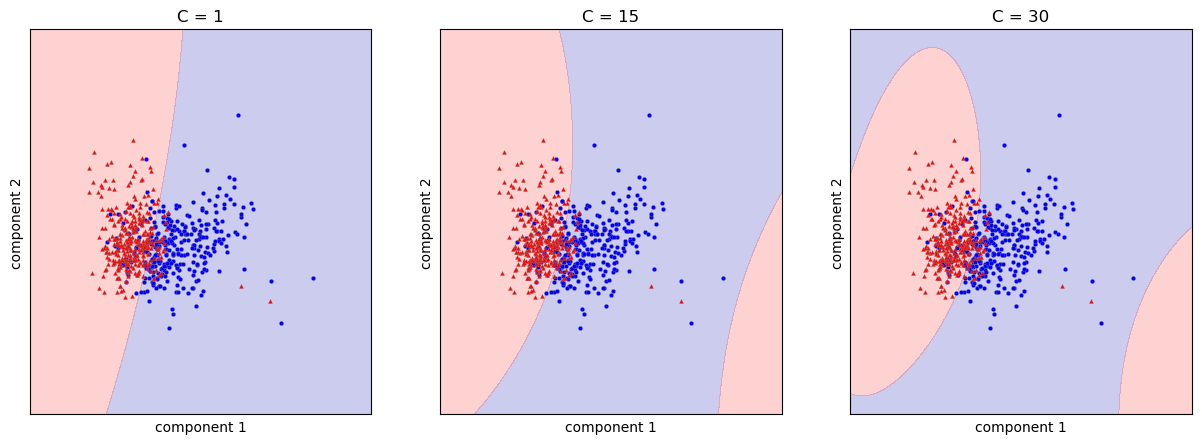

In [14]:
fig, axes = plt.subplots(1, 3, figsize = (15, 5))

# C값 1, 15, 30 에 따른 결정경계 시각화
for c_point, ax in zip([1, 15, 30], axes):
    c_svc_model = SVC(gamma = 0.5, C = c_point)
    c_svc_model.fit(pca_data, y_train)

    mglearn.plots.plot_2d_separator(c_svc_model, pca_data, fill = True, eps = 0.5, ax = ax,
                                    alpha = 0.2)
    mglearn.discrete_scatter(pca_data[:, 0], pca_data[:, 1], y_train, markeredgewidth = 0.2,
                             c = ["b", "r"], s = 3, ax = ax)
    ax.set_xlabel("component 1")
    ax.set_ylabel("component 2")
    ax.set_title(f"C = {c_point}")

plt.show()

In [15]:
# SVM gamma 값 1 ~ 30 에 따른 모델 성능 확인
scores = []

for gamma_point in [0.1, 0.5, 1, 5, 10, 20, 30]:
    svc = SVC(C = 10, gamma = gamma_point)
    svc.fit(scaled_x_train, y_train)
    train_score = svc.score(scaled_x_train, y_train)
    test_score = svc.score(scaled_x_test, y_test)

    print(f"SVM : gamma : {gamma_point}, train score : {train_score:.4f}, test score : {test_score:.4f}")

    scores.append([train_score, test_score])

SVM : gamma : 0.1, train score : 0.8635, test score : 0.8815
SVM : gamma : 0.5, train score : 0.8619, test score : 0.8852
SVM : gamma : 1, train score : 0.8619, test score : 0.9000
SVM : gamma : 5, train score : 0.8603, test score : 0.8926
SVM : gamma : 10, train score : 0.8683, test score : 0.8889
SVM : gamma : 20, train score : 0.8778, test score : 0.8926
SVM : gamma : 30, train score : 0.8889, test score : 0.8926


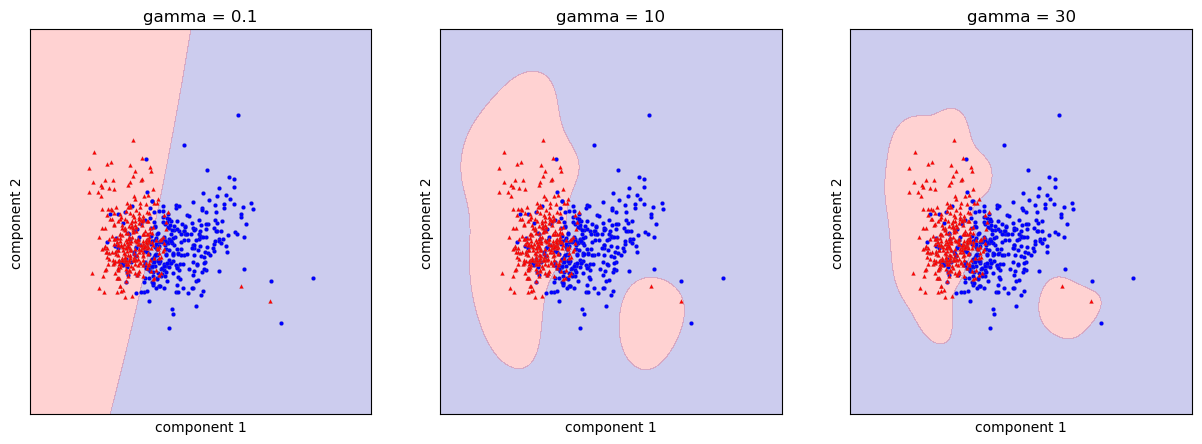

In [17]:
fig, axes = plt.subplots(1, 3, figsize = (15, 5))

# gamma 값 0.1, 10, 30 에 따른 결정경계 시각화
for gamma, ax in zip([0.1, 10, 30], axes):
    svc_model = SVC(gamma = gamma, C = 10)
    svc_model.fit(pca_data, y_train)

    mglearn.plots.plot_2d_separator(svc_model, pca_data, fill = True, eps = 0.5, ax = ax,
                                    alpha = 0.2)
    mglearn.discrete_scatter(pca_data[:, 0], pca_data[:, 1], y_train, markeredgewidth = 0.1,
                             c = ["b", "r"], s = 3, ax = ax)
    ax.set_xlabel("component 1")
    ax.set_ylabel("component 2")
    ax.set_title(f"gamma = {gamma}")
plt.show()